<a href="https://colab.research.google.com/github/cmburban/MAT-422/blob/main/MAT422_Section_3_5_3_6_KMeans_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Sections 3.5 and 3.6: K-means and Support Vector Machines

Topics: K-means, Support vector machine

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)

### 3.5 K-means Clustering

K-means is an unsupervised machine learning algorithm that groups data points into a specified number of clusters. Unlike supervised learning, it does not require known class labels to train the model.

The algorithm works by assigning each data point to the nearest cluster center, also called a centroid. It then recalculates each centroid as the mean of the points assigned to that cluster. These steps repeat until the cluster assignments or centroids stabilize.

The main objective of K-means is to minimize the **within-cluster sum of squared distances**, also called inertia. A smaller inertia indicates that points are closer to their assigned cluster centers, although inertia alone does not determine the best number of clusters.

In the following example, I will generate a dataset with three natural groups, apply K-means with three clusters, and visualize the resulting clusters and their centers.

Cluster centers:
[[-5.1989 -2.6887]
 [ 9.299   1.2333]
 [-6.5576  4.8014]]
Inertia: 202.2067992492687


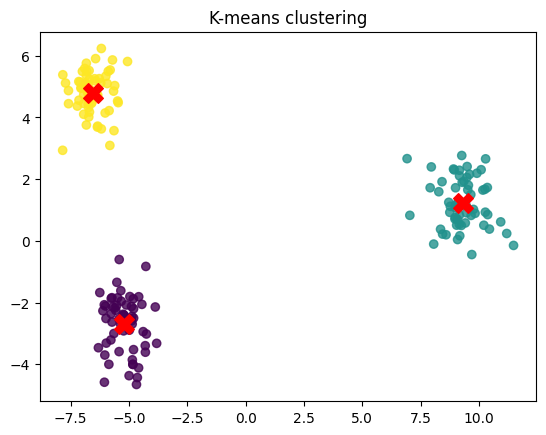

In [2]:
X, true_labels = make_blobs(n_samples=180, centers=3, cluster_std=0.7, random_state=422)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=422)
cluster_labels = kmeans.fit_predict(X)

print("Cluster centers:")
print(kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)

plt.scatter(X[:,0], X[:,1], c=cluster_labels, cmap="viridis", alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], marker="X", s=200, color="red")
plt.title("K-means clustering")
plt.show()

In [3]:
# Verify the number of clusters and the number of data points
print("Number of clusters:", len(kmeans.cluster_centers_))
print("Number of data points:", len(X))
print("Number of assigned labels:", len(kmeans.labels_))

# Check that every data point has a cluster assignment
print(
    "Every point has a cluster assignment:",
    len(kmeans.labels_) == len(X)
)

# Verify that the inertia is nonnegative
print("Inertia is nonnegative:", kmeans.inertia_ >= 0)

# Count the data points assigned to each cluster
cluster_counts = np.bincount(kmeans.labels_)
print("Points in each cluster:", cluster_counts)

Number of clusters: 3
Number of data points: 180
Number of assigned labels: 180
Every point has a cluster assignment: True
Inertia is nonnegative: True
Points in each cluster: [60 60 60]


### Interpretation

The K-means model grouped the data points into three distinct clusters. The red X markers represent the calculated centroids, which are the mean positions of the points assigned to each cluster. The printed inertia value of approximately 202.21 measures the total squared distance between each point and its assigned centroid. The verification checks confirm that the model assigned a cluster label to every data point and that the inertia is nonnegative. This example demonstrates how K-means identifies groups based on similarities in numerical features without requiring predefined class labels.

## 3.6 Support Vector Machines

A **support vector machine (SVM)** is a supervised machine learning algorithm used for classification. It learns a decision boundary that separates observations belonging to different classes.

The main idea of a linear SVM is to find a separating hyperplane that maximizes the margin between the two classes. The **margin** is the distance between the decision boundary and the nearest data points from each class.

These nearest data points are called **support vectors** because they help determine the position of the decision boundary. The parameter \(C\) controls the trade-off between having a wider margin and penalizing classification errors on the training data.

In the following example, I will train a linear SVM on a two-dimensional dataset. I will examine its training accuracy, count its support vectors, and visualize the decision boundary and margins.

Training accuracy: 0.9571428571428572
Number of support vectors: [13 13]


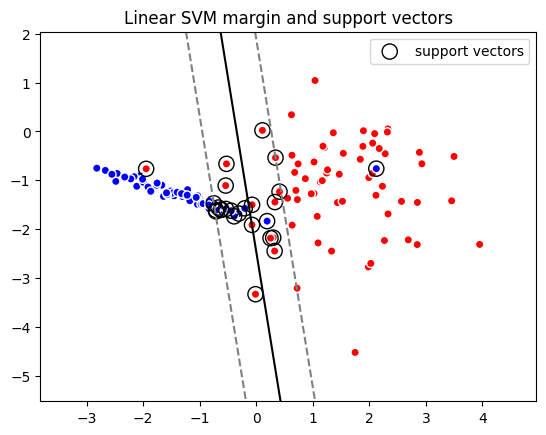

In [4]:
Xc, yc = make_classification(n_samples=140, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, class_sep=1.3, random_state=422)
svm = SVC(kernel="linear", C=1.0)
svm.fit(Xc, yc)
pred = svm.predict(Xc)

print("Training accuracy:", accuracy_score(yc, pred))
print("Number of support vectors:", svm.n_support_)

xx, yy = np.meshgrid(np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 150),
                     np.linspace(Xc[:,1].min()-1, Xc[:,1].max()+1, 150))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(Xc[:,0], Xc[:,1], c=yc, cmap="bwr", edgecolor="white")
plt.scatter(svm.support_vectors_[:,0], svm.support_vectors_[:,1], s=120, facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear SVM margin and support vectors")
plt.legend()
plt.show()

In [7]:
# Verify the model's predictions and support vectors
predictions = svm.predict(Xc)

print("Number of data points:", len(Xc))
print("Number of predictions:", len(predictions))
print("Number of support vectors:", len(svm.support_))
print("Support vectors per class:", svm.n_support_)

# Verify the accuracy using the actual labels
accuracy = accuracy_score(yc, predictions)
print("Accuracy is between 0 and 1:", 0 <= accuracy <= 1)
print(f"Verified training accuracy: {accuracy:.2%}")

# Verify that both classes have support vectors
print(
    "Both classes have support vectors:",
    np.all(svm.n_support_ > 0)
)

Number of data points: 140
Number of predictions: 140
Number of support vectors: 26
Support vectors per class: [13 13]
Accuracy is between 0 and 1: True
Verified training accuracy: 95.71%
Both classes have support vectors: True


### Interpretation

The linear SVM achieved a training accuracy of approximately 95.71%, meaning that it correctly classified most of the training observations. The model identified 26 support vectors, with 13 from each class. These points help determine the position of the decision boundary and its margins. The graph illustrates how the SVM separates the two classes while allowing some classification errors. Because this accuracy was measured on the training data, additional testing would be needed to evaluate how well the model generalizes to unseen observations.

## End of Notebook Reflection

In Sections 3.5 and 3.6, I learned about two different machine learning approaches: K-means clustering and support vector machines. K-means is an unsupervised learning algorithm that groups data points into clusters based on their similarity and distance from cluster centers. In contrast, an SVM is a supervised learning algorithm that learns a decision boundary to separate labeled classes.

The K-means example demonstrated how cluster centers and inertia help describe the resulting groups. The SVM example showed how a decision boundary, margins, and support vectors help classify data. The model achieved approximately 95.71% training accuracy, and the verification checks confirmed that both classes had support vectors. These examples helped me understand how clustering and classification solve different types of machine learning problems.

## References

[Mathematical Methods in Data Science - Elsevier (2023)](https://doi.org/10.1016/B978-0-44-318679-0.00007-7)

[Numpy - Singular Value Decomposition](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)

[Matplotlib](https://matplotlib.org/stable/)

[Scikit-learn Developers](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

[OpenAI - ChatGPT (2026)](https://chatgpt.com)

## Submission Checklist

- I explained each concept in words before or after the code. [DONE]
- I verified important claims numerically or visually. [DONE]
- I changed or extended at least one example so the notebook reflects my own work. [DONE]
- I ran the notebook from top to bottom without errors. [DONE]
- I saved the notebook from Google Colab directly to GitHub, following the course instructions. [DONE]